# MOHAMMAD IQFAR
# H061251064 (B)
# TUGAS AI GEOFISIKA — Notebook Eksekusi (Hasil Run dari 5 Prompt)

Notebook ini adalah **implementasi yang bisa dijalankan** dari lima prompt work specification pada notebook `TUGAS 1 AI GEOFISIKA.ipynb`
(kerangka **P = ⟨R, T, C, I, K, O, Q, V⟩**).

**Cara pakai**
1. Jalankan sel dari atas ke bawah (`Kernel → Restart & Run All`).
2. Library yang dipakai hanya **NumPy, pandas, matplotlib** (sesuai Constraints pada prompt).
3. Karena placeholder data pada prompt (`[DATA_SEISMOGRAM]`, `[DATA_MAGNETIK]`, dst.) belum berisi file nyata, setiap bagian memakai **data sintetis** dengan "kebenaran" (ground truth) yang diketahui, sehingga kriteria **Quality (Q)** dan **Verification (V)** bisa benar-benar diuji.
4. Untuk memakai **data lapangan sendiri**, ganti bagian bertanda `# >>> GANTI DENGAN DATA ANDA` di tiap bagian.

| Bagian | Metode | Inti perhitungan |
|---|---|---|
| 1 | Seismik | Picking P/S → S−P → diagram Wadati → jarak episenter |
| 2 | Gravitasi | Isostasi Airy vs Pratt → root kompensasi |
| 3 | Geomagnetik | Koreksi diurnal & IGRF → anomali residual → zona anomali |
| 4 | Geolistrik | ρa = K·V/I → kurva sounding → flag anomali |
| 5 | Georadar | d = v·t/2 → radargram → reflektor |

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

# Seed tetap agar hasil dapat direproduksi
SEED = 42
print("NumPy", np.__version__, "| pandas", pd.__version__)

NumPy 2.4.4 | pandas 3.0.2


---
# 1. Metode Seismik — Diagram Wadati

**Prompt (ringkas):** hitung waktu tiba P dan S dari seismogram, tentukan selisih S−P, estimasi jarak episenter dengan diagram Wadati; nyatakan asumsi $V_p$, $V_s$.

**Teori singkat**

Untuk sumber pada jarak hiposenter $D$:

$$t_P = t_0 + \frac{D}{V_p},\qquad t_S = t_0 + \frac{D}{V_s}$$

$$t_S - t_P = D\left(\frac{1}{V_s}-\frac{1}{V_p}\right)\;\Rightarrow\; D = (t_S-t_P)\,\frac{V_p V_s}{V_p-V_s}$$

Pada diagram Wadati ($t_S-t_P$ terhadap $t_P$), data berupa **garis lurus** dengan kemiringan

$$m = \frac{V_p}{V_s}-1$$

dan titik potong sumbu-$t_P$ memberi **origin time** $t_0$ (karena saat $t_S-t_P=0$, $D=0$, $t_P=t_0$).

**Alur:** seismogram → STA/LTA picking P & S → tabel S−P → regresi linear → $V_p/V_s$, $t_0$ → jarak.

Waktu tiba P  : benar = 10.00 s | hasil picking = 10.03 s
Waktu tiba S  : benar = 16.40 s | hasil picking = 16.27 s
S-P           : benar = 6.40 s | hasil picking = 6.24 s


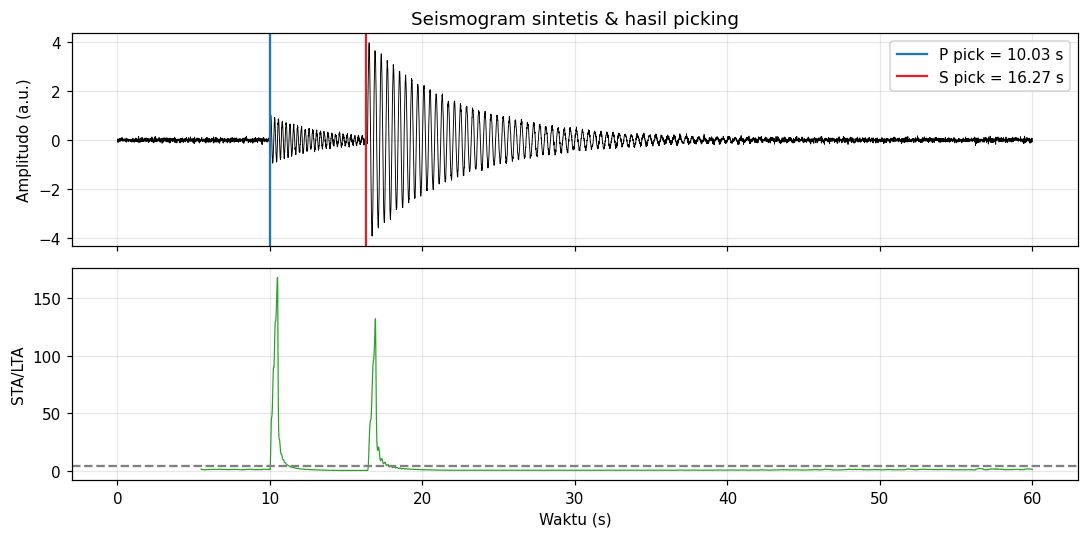

In [14]:
# ============ 1A. Seismogram sintetis 1 stasiun + picking otomatis STA/LTA ============
rng = np.random.default_rng(SEED)

FS = 100.0                          # Hz
t = np.arange(0, 60, 1/FS)          # detik

def synth_seismogram(tp, ts, rng):
    s = 0.05 * rng.standard_normal(t.size)                       # noise latar
    mP = t >= tp
    mS = t >= ts
    s += 1.0 * np.exp(-(t - tp)/3.0) * np.sin(2*np.pi*4.0*(t - tp)) * mP    # fase P (frekuensi lebih tinggi)
    s += 4.0 * np.exp(-(t - ts)/6.0) * np.sin(2*np.pi*2.5*(t - ts)) * mS    # fase S (amplitudo lebih besar)
    return s

def sta_lta(x, fs, sta_s=0.5, lta_s=5.0):
    cf = x**2
    c = np.concatenate([[0], np.cumsum(cf)])
    ns, nl = int(sta_s*fs), int(lta_s*fs)
    sta = np.zeros_like(cf); lta = np.zeros_like(cf)
    for i in range(nl, cf.size):
        sta[i] = (c[i+1] - c[i+1-ns]) / ns
        lta[i] = (c[i+1-ns] - c[i+1-ns-nl]) / nl if i+1-ns-nl >= 0 else np.nan
    with np.errstate(invalid="ignore", divide="ignore"):
        return sta/lta, sta

def pick_PS(x, fs, thr_p=4.0, thr_s=6.0):
    ratio, sta = sta_lta(x, fs)
    ip = int(np.argmax(ratio > thr_p))                     # trigger pertama = P
    # S: setelah P+1 s, STA melonjak dibanding energi rata-rata awal koda P
    ref = np.mean(x[ip:ip+int(1.0*fs)]**2)
    start = ip + int(1.0*fs)
    cand = np.where(sta[start:] > thr_s*ref)[0]
    isx = start + int(cand[0])
    # koreksi lag trigger (STA trailing 0.5 s): geser mundur setengah jendela
    return (ip/fs) , (isx/fs - 0.25), ratio

TP_TRUE, TS_TRUE = 10.00, 16.40
seis = synth_seismogram(TP_TRUE, TS_TRUE, rng)
tp_pick, ts_pick, ratio = pick_PS(seis, FS)

print(f"Waktu tiba P  : benar = {TP_TRUE:.2f} s | hasil picking = {tp_pick:.2f} s")
print(f"Waktu tiba S  : benar = {TS_TRUE:.2f} s | hasil picking = {ts_pick:.2f} s")
print(f"S-P           : benar = {TS_TRUE-TP_TRUE:.2f} s | hasil picking = {ts_pick-tp_pick:.2f} s")

fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
ax[0].plot(t, seis, lw=0.6, color="k")
ax[0].axvline(tp_pick, color="tab:blue", label=f"P pick = {tp_pick:.2f} s")
ax[0].axvline(ts_pick, color="tab:red", label=f"S pick = {ts_pick:.2f} s")
ax[0].set_ylabel("Amplitudo (a.u.)"); ax[0].legend(loc="upper right")
ax[0].set_title("Seismogram sintetis & hasil picking")
ax[1].plot(t, ratio, lw=0.8, color="tab:green"); ax[1].axhline(4.0, color="gray", ls="--")
ax[1].set_ylabel("STA/LTA"); ax[1].set_xlabel("Waktu (s)")
plt.tight_layout(); plt.show()

,Stasiun,tP (s),tS (s),S-P (s),Jarak estimasi (km),Jarak benar (km),Galat (km)
0,ST01,17.024,20.652,3.628,29.517,30.000,-0.483
1,ST02,21.234,27.889,6.655,54.142,55.000,-0.858
2,ST03,25.275,34.949,9.674,78.709,80.000,-1.291
3,ST04,30.242,43.901,13.658,111.121,110.000,1.121
4,ST05,35.134,52.508,17.374,141.352,140.000,1.352
5,ST06,40.430,60.998,20.568,167.337,170.000,-2.663



Slope m          = 0.7375  -> Vp/Vs = 1.737   (benar: 1.73)
Origin time t0   = 12.05 s            (benar: 12.0)
R^2 regresi      = 0.9984
Asumsi Vp = 6.0 km/s -> Vs estimasi = 3.453 km/s
RMSE jarak       = 1.46 km


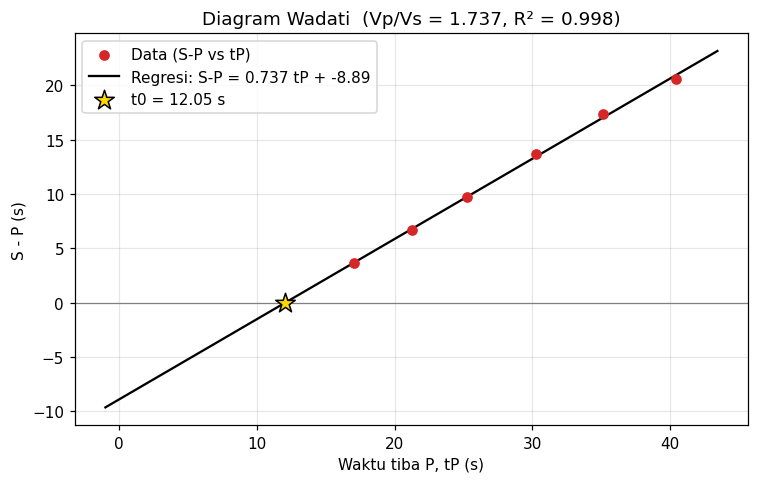

In [15]:
# ============ 1B. Diagram Wadati dari 6 stasiun ============
# >>> GANTI DENGAN DATA ANDA: isi tP, tS (detik, UTC relatif) dan nama stasiun dari hasil picking nyata
rng = np.random.default_rng(SEED + 1)

VP = 6.0                 # km/s  (asumsi: kerak atas; ganti dengan nilai dari literatur lokal)
VPVS_TRUE = 1.73         # hanya untuk membangkitkan data sintetis
VS = VP / VPVS_TRUE
T0_TRUE = 12.0           # s
D_TRUE = np.array([30, 55, 80, 110, 140, 170.0])        # km (jarak hiposenter sintetis)
stations = [f"ST{i+1:02d}" for i in range(D_TRUE.size)]

tP = T0_TRUE + D_TRUE/VP + rng.normal(0, 0.10, D_TRUE.size)
tS = T0_TRUE + D_TRUE/VS + rng.normal(0, 0.15, D_TRUE.size)

df = pd.DataFrame({"Stasiun": stations, "tP (s)": tP, "tS (s)": tS})
df["S-P (s)"] = df["tS (s)"] - df["tP (s)"]

# Regresi linear Wadati: (tS - tP) = m * tP + c
m, c = np.polyfit(df["tP (s)"], df["S-P (s)"], 1)
pred = m*df["tP (s)"] + c
r2 = 1 - np.sum((df["S-P (s)"]-pred)**2) / np.sum((df["S-P (s)"]-df["S-P (s)"].mean())**2)

vpvs = m + 1
t0_est = -c / m
vs_est = VP / vpvs

# Jarak: D = (tS-tP) * Vp*Vs/(Vp-Vs)
df["Jarak estimasi (km)"] = df["S-P (s)"] * VP*vs_est/(VP - vs_est)
df["Jarak benar (km)"] = D_TRUE
df["Galat (km)"] = df["Jarak estimasi (km)"] - df["Jarak benar (km)"]

display(df.round(3))
print(f"\nSlope m          = {m:.4f}  -> Vp/Vs = {vpvs:.3f}   (benar: {VPVS_TRUE})")
print(f"Origin time t0   = {t0_est:.2f} s            (benar: {T0_TRUE})")
print(f"R^2 regresi      = {r2:.4f}")
print(f"Asumsi Vp = {VP} km/s -> Vs estimasi = {vs_est:.3f} km/s")
print(f"RMSE jarak       = {np.sqrt(np.mean(df['Galat (km)']**2)):.2f} km")

xx = np.linspace(min(0, t0_est)-1, df["tP (s)"].max()+3, 100)
plt.figure(figsize=(7, 4.5))
plt.scatter(df["tP (s)"], df["S-P (s)"], color="tab:red", zorder=3, label="Data (S-P vs tP)")
plt.plot(xx, m*xx + c, color="k", label=f"Regresi: S-P = {m:.3f} tP + {c:.2f}")
plt.axhline(0, color="gray", lw=0.8)
plt.scatter([t0_est], [0], marker="*", s=180, color="gold", edgecolor="k", zorder=4, label=f"t0 = {t0_est:.2f} s")
plt.xlabel("Waktu tiba P, tP (s)"); plt.ylabel("S - P (s)")
plt.title(f"Diagram Wadati  (Vp/Vs = {vpvs:.3f}, R² = {r2:.3f})")
plt.legend(); plt.tight_layout(); plt.show()

In [16]:
# ============ 1C. Verifikasi (V): cek satuan & contoh numerik satu stasiun ============
i = 2
sp = df.loc[i, "S-P (s)"]
D_manual = sp * VP*vs_est/(VP - vs_est)
print(f"Contoh numerik stasiun {df.loc[i,'Stasiun']}:")
print(f"  S-P = {sp:.3f} s")
print(f"  D   = {sp:.3f} s x ({VP:.2f} x {vs_est:.3f})/({VP:.2f} - {vs_est:.3f}) km/s = {D_manual:.2f} km")
print(f"  Jarak benar (sintetis) = {D_TRUE[i]:.1f} km  | galat = {D_manual-D_TRUE[i]:+.2f} km")
# Cek dimensi: [s] * [km/s]*[km/s] / [km/s] = [km]  -> konsisten
print("Cek dimensi: s x (km/s) = km  OK")
print("Catatan: bandingkan dengan katalog BMKG/USGS untuk event nyata saat memakai data lapangan.")

Contoh numerik stasiun ST03:
  S-P = 9.674 s
  D   = 9.674 s x (6.00 x 3.453)/(6.00 - 3.453) km/s = 78.71 km
  Jarak benar (sintetis) = 80.0 km  | galat = -1.29 km
Cek dimensi: s x (km/s) = km  OK
Catatan: bandingkan dengan katalog BMKG/USGS untuk event nyata saat memakai data lapangan.


---
# 2. Metode Gravitasi — Isostasi Airy vs Pratt

**Prompt (ringkas):** turunkan hubungan isostasi Airy untuk topografi, hitung ketebalan root (Δh / r), bandingkan dengan model Pratt; nyatakan asumsi densitas kerak & mantel.

**Penurunan**

*Airy* (densitas kerak seragam $\rho_c$, ketebalan bervariasi). Kesetimbangan tekanan pada dasar root:

$$\rho_c\,h + \rho_c\,r = \rho_m\,r \;\Rightarrow\; \boxed{\,r = \frac{\rho_c}{\rho_m-\rho_c}\,h\,}$$

*Pratt* (kedalaman kompensasi $D$ tetap, densitas bervariasi). Massa kolom sama dengan kolom referensi $\rho_0 D$:

$$\rho_i\,(D+h_i)=\rho_0 D \;\Rightarrow\; \boxed{\,\rho_i = \rho_0\,\frac{D}{D+h_i}\,}$$

**Asumsi (sumber: Fowler, *The Solid Earth*):** $\rho_c = 2800$ kg/m³, $\rho_m = 3300$ kg/m³, kerak referensi $T = 35$ km; Pratt: $D = 100$ km, $\rho_0 = 2800$ kg/m³.

In [17]:
# ============ 2A. Hitung root Airy & densitas Pratt ============
# >>> GANTI DENGAN DATA ANDA: elevasi h (m) dan parameter densitas
RHO_C = 2800.0     # kg/m^3 (kerak)
RHO_M = 3300.0     # kg/m^3 (mantel)
T_REF = 35e3       # m, ketebalan kerak referensi
D_COMP = 100e3     # m, kedalaman kompensasi Pratt
RHO_0 = 2800.0     # kg/m^3, densitas referensi Pratt
G = 9.81

h = np.array([0.5, 1, 2, 3, 4, 5, 6, 8]) * 1e3          # elevasi (m)

root_airy = h * RHO_C / (RHO_M - RHO_C)                 # m
moho_airy = T_REF + h + root_airy                       # tebal total kerak (m) di bawah gunung
rho_pratt = RHO_0 * D_COMP / (D_COMP + h)               # kg/m^3

tab = pd.DataFrame({
    "h (km)": h/1e3,
    "Root Airy r (km)": root_airy/1e3,
    "Tebal kerak Airy (km)": moho_airy/1e3,
    "Rapat massa Pratt (kg/m3)": rho_pratt,
    "Delta rho Pratt (kg/m3)": rho_pratt - RHO_0,
})
display(tab.round(2))
print(f"Rasio r/h (Airy) = {RHO_C/(RHO_M-RHO_C):.2f}  ->  setiap 1 km topografi ~ {RHO_C/(RHO_M-RHO_C):.1f} km root")

,h (km),Root Airy r (km),Tebal kerak Airy (km),Rapat massa Pratt (kg/m3),Delta rho Pratt (kg/m3)
0,0.500,2.800,38.300,"2,786.070",-13.930
1,1.000,5.600,41.600,"2,772.280",-27.720
2,2.000,11.200,48.200,"2,745.100",-54.900
3,3.000,16.800,54.800,"2,718.450",-81.550
4,4.000,22.400,61.400,"2,692.310",-107.690
5,5.000,28.000,68.000,"2,666.670",-133.330
6,6.000,33.600,74.600,"2,641.510",-158.490
7,8.000,44.800,87.800,"2,592.590",-207.410


Rasio r/h (Airy) = 5.60  ->  setiap 1 km topografi ~ 5.6 km root


In [18]:
# ============ 2B. Verifikasi kesetimbangan tekanan (V) ============
# Tekanan di kedalaman kompensasi Dc (dari muka laut) harus sama untuk kolom referensi & kolom gunung.
Dc = T_REF + 80e3              # 115 km: kedalaman bidang kompensasi, di bawah root terdalam (T_REF + r maks)

P_ref = G * (RHO_C*T_REF + RHO_M*(Dc - T_REF))
P_airy = G * (RHO_C*(h + T_REF + root_airy) + RHO_M*(Dc - T_REF - root_airy))
print("Cek Airy  : selisih tekanan (Pa) per elevasi ->", np.round(P_airy - P_ref, 6))
print("Cek Pratt : rho_i (D+h) - rho_0 D (kg/m^2)    ->", np.round(rho_pratt*(D_COMP+h) - RHO_0*D_COMP, 6))
assert np.allclose(P_airy, P_ref) and np.allclose(rho_pratt*(D_COMP+h), RHO_0*D_COMP)
print("Dimensi: [kg/m3]*[m] * [m/s2] = Pa  OK")
print(f"Orde besaran root untuk 5 km topografi: {5*RHO_C/(RHO_M-RHO_C):.1f} km (literatur: puluhan km)  OK")

Cek Airy  : selisih tekanan (Pa) per elevasi -> [0. 0. 0. 0. 0. 0. 0. 0.]
Cek Pratt : rho_i (D+h) - rho_0 D (kg/m^2)    -> [0. 0. 0. 0. 0. 0. 0. 0.]
Dimensi: [kg/m3]*[m] * [m/s2] = Pa  OK
Orde besaran root untuk 5 km topografi: 28.0 km (literatur: puluhan km)  OK


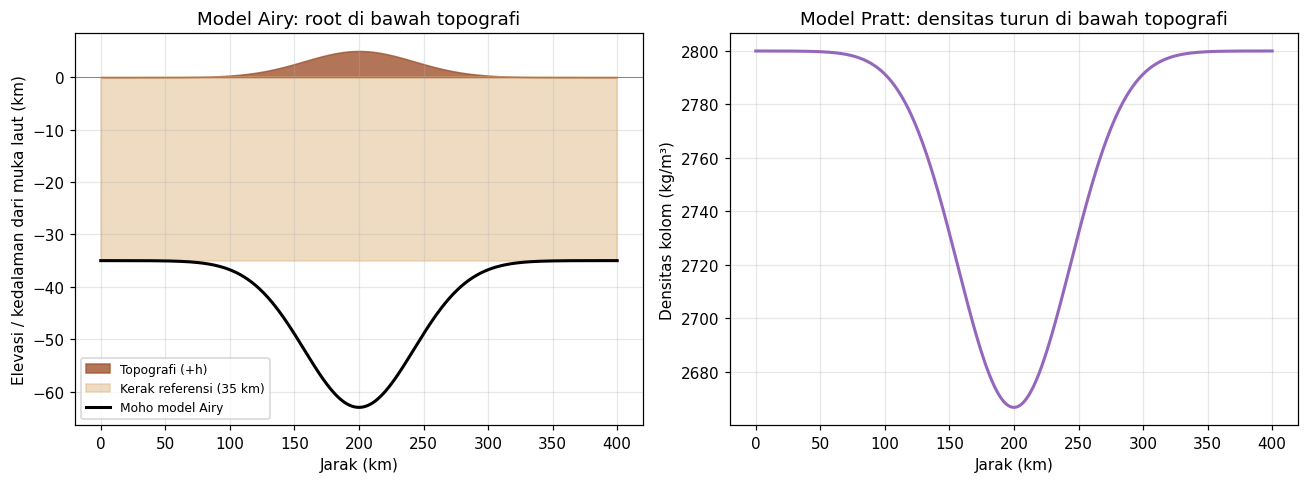

In [19]:
# ============ 2C. Profil penampang: gunung Gaussian ============
x = np.linspace(0, 400, 401)                            # km
elev = 5000*np.exp(-((x-200)/60)**2)                    # m
moho = (T_REF + elev + elev*RHO_C/(RHO_M-RHO_C))/1e3    # km (Airy)
rho_x = RHO_0*D_COMP/(D_COMP+elev)                      # Pratt

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].fill_between(x, 0, elev/1e3, color="sienna", alpha=0.8, label="Topografi (+h)")
ax[0].fill_between(x, 0, -(T_REF/1e3)*np.ones_like(x), color="burlywood", alpha=0.5, label="Kerak referensi (35 km)")
ax[0].plot(x, -(moho - elev/1e3), "k", lw=2, label="Moho model Airy")
ax[0].axhline(0, color="gray", lw=0.6)
ax[0].set_xlabel("Jarak (km)"); ax[0].set_ylabel("Elevasi / kedalaman dari muka laut (km)")
ax[0].set_title("Model Airy: root di bawah topografi"); ax[0].legend(loc="lower left", fontsize=8)

ax[1].plot(x, rho_x, color="tab:purple", lw=2)
ax[1].set_xlabel("Jarak (km)"); ax[1].set_ylabel("Densitas kolom (kg/m³)")
ax[1].set_title("Model Pratt: densitas turun di bawah topografi")
plt.tight_layout(); plt.show()

**Interpretasi fisis (O):**
- **Airy**: topografi dikompensasi oleh *ketebalan* kerak (root). Densitas kerak konstan; untuk $h=5$ km diperlukan root ≈ 28 km. Cocok untuk pegunungan besar dengan akar kerak tebal (Himalaya, Andes).
- **Pratt**: topografi dikompensasi oleh *variasi densitas* di atas kedalaman kompensasi $D$ yang tetap; tidak ada root. Hasil: blok tinggi berdensitas lebih rendah. Lebih mewakili kompensasi pada litosfer termal (punggungan tengah samudra).
- Keduanya sama-sama menjamin tekanan di bidang kompensasi seragam, namun implikasi struktur dalam berbeda → ini yang dibedakan lewat data gravitasi (anomali Bouguer negatif besar di atas gunung mendukung Airy).

---
# 3. Metode Geomagnetik — Koreksi IGRF & Anomali Residual

**Prompt (ringkas):** koreksi IGRF pada data medan magnet total, hitung anomali residual, identifikasi zona anomali positif/negatif signifikan.

**Rumus**

$$\Delta T(x,y) = F_{\text{obs, terkoreksi diurnal}}(x,y) - F_{\text{IGRF}}(x,y)$$

dengan koreksi diurnal memakai stasiun base: $F_{\text{terkoreksi}}(t)=F_{\text{obs}}(t)-\big[B(t)-B_{\text{ref}}\big]$.

> **Catatan penting (Constraints):** nilai IGRF **tidak dihitung ulang** di sini karena prompt melarang library pihak ketiga tanpa sumber jelas.
> Nilai IGRF referensi harus diambil dari **kalkulator resmi NOAA/NGDC** untuk lokasi & tanggal survei, lalu dimasukkan pada variabel `IGRF_F0`, `IGRF_GRAD_*` di bawah. Nilai di sini adalah **placeholder sintetis**.
> Data mentah **tidak diubah**; hasil koreksi disimpan pada kolom baru.

In [20]:
# ============ 3A. Data survei sintetis (grid 21x21, spasi 10 m) ============
rng = np.random.default_rng(SEED + 2)

# >>> GANTI DENGAN DATA ANDA: baca CSV (x, y, waktu_jam, F_obs) dan base station (waktu_jam, B)
IGRF_F0 = 43500.0          # nT  (placeholder; ambil dari kalkulator IGRF NOAA)
IGRF_GRAD_X = 0.002        # nT/m ke timur  (placeholder)
IGRF_GRAD_Y = 0.020        # nT/m ke utara  (placeholder)
INC_DEG, DEC_DEG = -30.0, 0.0    # inklinasi & deklinasi (placeholder)

xs = np.arange(0, 201, 10.0)
ys = np.arange(0, 201, 10.0)
X, Y = np.meshgrid(xs, ys)

# arah medan utama (x=Timur, y=Utara, z=ke bawah)
I, D_ = np.radians(INC_DEG), np.radians(DEC_DEG)
Fhat = np.array([np.cos(I)*np.sin(D_), np.cos(I)*np.cos(D_), np.sin(I)])

def dipole_anomaly(X, Y, xs0, ys0, depth, A):
    # anomali total-field benda terinduksi (pendekatan dipol/bola), nT
    rx, ry, rz = X - xs0, Y - ys0, -depth*np.ones_like(X)
    r = np.sqrt(rx**2 + ry**2 + rz**2)
    cosang = (Fhat[0]*rx + Fhat[1]*ry + Fhat[2]*rz) / r
    return A * (3*cosang**2 - 1) / r**3

anom_true = (dipole_anomaly(X, Y, 80, 100, 15, 3.0e5)
             + dipole_anomaly(X, Y, 150, 60, 10, -1.5e5))        # benda ke-2 magnetisasi berlawanan

# Waktu survei: 20 s per titik, ular (zig-zag) per lintasan
n = X.size
t_hours = 9.0 + np.arange(n)*20/3600
diurnal = 12*np.sin(2*np.pi*(t_hours-6)/24) + 4*np.sin(2*np.pi*(t_hours-6)/3)

igrf_grid = IGRF_F0 + IGRF_GRAD_X*X + IGRF_GRAD_Y*Y
F_obs = igrf_grid.ravel() + diurnal + anom_true.ravel() + rng.normal(0, 1.5, n)

# Base station tiap 1 menit
tb = np.arange(t_hours[0]-0.1, t_hours[-1]+0.1, 1/60)
IGRF_BASE = IGRF_F0
B = IGRF_BASE + 12*np.sin(2*np.pi*(tb-6)/24) + 4*np.sin(2*np.pi*(tb-6)/3) + rng.normal(0, 0.5, tb.size)

raw = pd.DataFrame({"x (m)": X.ravel(), "y (m)": Y.ravel(), "waktu (jam)": t_hours, "F_obs (nT)": F_obs})
print("Data mentah (tidak diubah):", raw.shape)
display(raw.head())

Data mentah (tidak diubah): (441, 4)


,x (m),y (m),waktu (jam),F_obs (nT)
0,0.000,0.000,9.000,"43,510.699"
1,10.000,0.000,9.006,"43,508.787"
2,20.000,0.000,9.011,"43,509.234"
3,30.000,0.000,9.017,"43,510.565"
4,40.000,0.000,9.022,"43,510.218"


Statistik anomali: mean = 0.08 nT | std = 9.47 nT | min = -95.6 | max = 74.5
RMSE terhadap anomali sebenarnya (sintetis): 1.62 nT


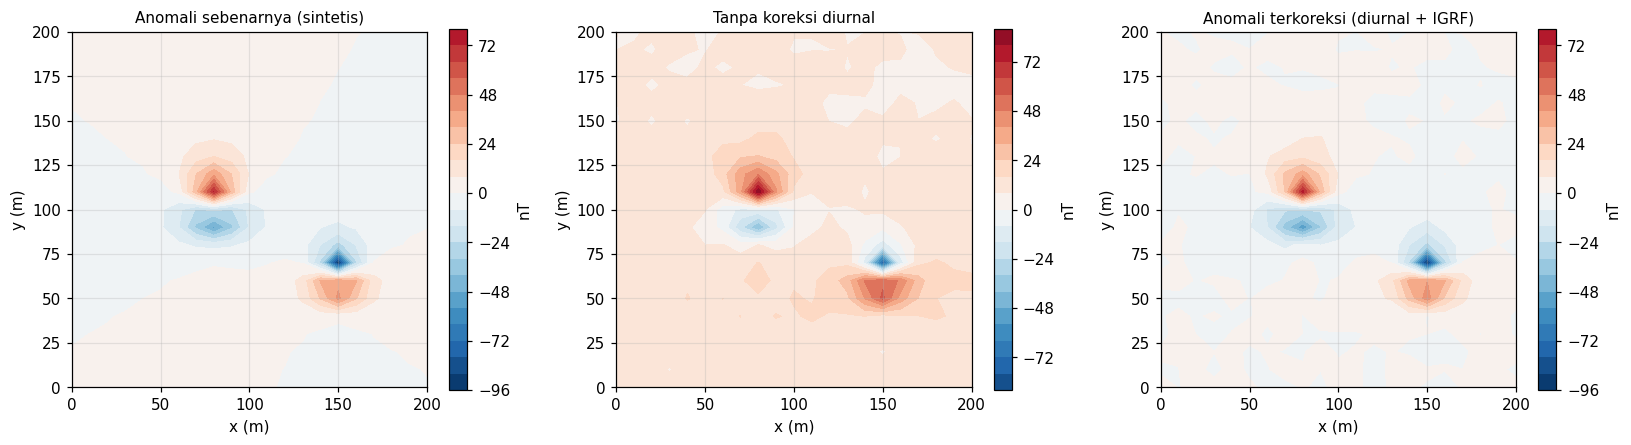

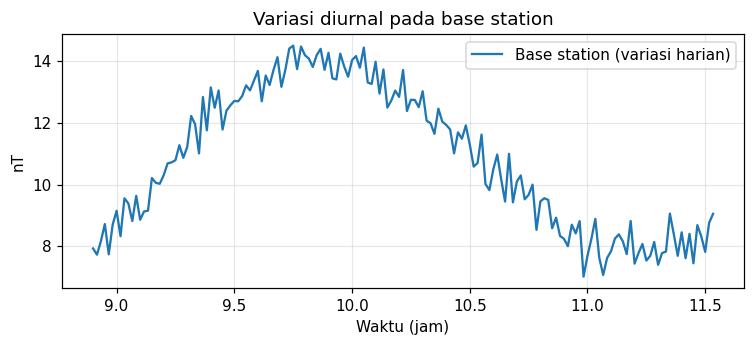

In [21]:
# ============ 3B. Koreksi diurnal -> koreksi IGRF -> anomali residual ============
data = raw.copy()                                            # data mentah dipertahankan
B_at_obs = np.interp(data["waktu (jam)"], tb, B)
data["Koreksi diurnal (nT)"] = B_at_obs - IGRF_BASE
data["F_terkoreksi (nT)"]    = data["F_obs (nT)"] - data["Koreksi diurnal (nT)"]
data["IGRF (nT)"]            = (IGRF_F0 + IGRF_GRAD_X*data["x (m)"] + IGRF_GRAD_Y*data["y (m)"])
data["Anomali dT (nT)"]      = data["F_terkoreksi (nT)"] - data["IGRF (nT)"]

dT = data["Anomali dT (nT)"].to_numpy().reshape(X.shape)
mu, sd = dT.mean(), dT.std()
print(f"Statistik anomali: mean = {mu:.2f} nT | std = {sd:.2f} nT | min = {dT.min():.1f} | max = {dT.max():.1f}")
print(f"RMSE terhadap anomali sebenarnya (sintetis): {np.sqrt(np.mean((dT-anom_true)**2)):.2f} nT")

fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
for a, Z, ttl in zip(ax, [anom_true, F_obs.reshape(X.shape)-igrf_grid, dT],
                     ["Anomali sebenarnya (sintetis)", "Tanpa koreksi diurnal", "Anomali terkoreksi (diurnal + IGRF)"]):
    cs = a.contourf(X, Y, Z, levels=21, cmap="RdBu_r", vmin=-np.abs(anom_true).max(), vmax=np.abs(anom_true).max())
    a.set_title(ttl, fontsize=10); a.set_xlabel("x (m)"); a.set_ylabel("y (m)"); a.set_aspect("equal")
    plt.colorbar(cs, ax=a, label="nT", shrink=0.85)
plt.tight_layout(); plt.show()

plt.figure(figsize=(8, 3))
plt.plot(tb, B-IGRF_BASE, label="Base station (variasi harian)")
plt.xlabel("Waktu (jam)"); plt.ylabel("nT"); plt.title("Variasi diurnal pada base station"); plt.legend(); plt.show()

,Zona,Jumlah titik,Puncak dT (nT),x puncak (m),y puncak (m)
0,Negatif,7,-95.554,150.000,70.000
1,Positif,9,74.542,80.000,110.000
2,Negatif,11,-54.018,80.000,90.000
3,Positif,9,44.398,150.000,50.000


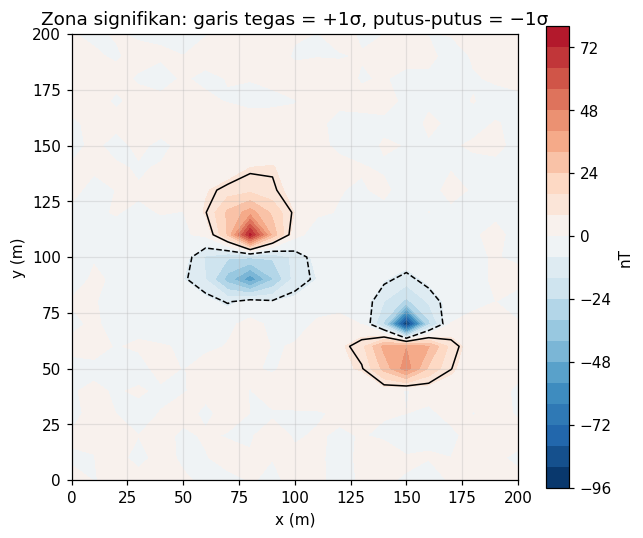

In [22]:
# ============ 3C. Identifikasi zona anomali signifikan (|dT - mean| > 1 sigma), komponen terhubung ============
def label_regions(mask):
    lab = np.zeros(mask.shape, int); k = 0
    for i in range(mask.shape[0]):
        for j in range(mask.shape[1]):
            if mask[i, j] and lab[i, j] == 0:
                k += 1; stack = [(i, j)]; lab[i, j] = k
                while stack:
                    a, b = stack.pop()
                    for da, db in ((1,0),(-1,0),(0,1),(0,-1)):
                        na, nb = a+da, b+db
                        if 0 <= na < mask.shape[0] and 0 <= nb < mask.shape[1] and mask[na, nb] and lab[na, nb] == 0:
                            lab[na, nb] = k; stack.append((na, nb))
    return lab, k

rows = []
for sign, name in ((+1, "Positif"), (-1, "Negatif")):
    mask = sign*(dT - mu) > 1.0*sd
    lab, k = label_regions(mask)
    for r in range(1, k+1):
        sel = lab == r
        if sel.sum() < 3:        # abaikan zona terlalu kecil (<3 titik)
            continue
        idx = np.argmax(np.abs(np.where(sel, dT, 0)))
        iy, ix = np.unravel_index(idx, dT.shape)
        rows.append({"Zona": name, "Jumlah titik": int(sel.sum()),
                     "Puncak dT (nT)": dT[iy, ix], "x puncak (m)": xs[ix], "y puncak (m)": ys[iy]})
zones = pd.DataFrame(rows).sort_values("Puncak dT (nT)", key=np.abs, ascending=False).reset_index(drop=True)
display(zones)

plt.figure(figsize=(6, 5))
cs = plt.contourf(X, Y, dT, levels=21, cmap="RdBu_r", vmin=-np.abs(dT).max(), vmax=np.abs(dT).max())
plt.contour(X, Y, dT, levels=[mu-sd, mu+sd], colors=["k","k"], linestyles=["--","-"], linewidths=1)
plt.colorbar(cs, label="nT"); plt.gca().set_aspect("equal")
plt.title("Zona signifikan: garis tegas = +1σ, putus-putus = −1σ"); plt.xlabel("x (m)"); plt.ylabel("y (m)")
plt.tight_layout(); plt.show()

In [23]:
# ============ 3D. Verifikasi (V) ============
print("Verifikasi:")
print(f"  1) IGRF yang dipakai di titik (x=100,y=100): "
      f"{IGRF_F0 + IGRF_GRAD_X*100 + IGRF_GRAD_Y*100:.2f} nT  -> bandingkan dengan kalkulator IGRF NOAA untuk lokasi & tanggal yang sama.")
print(f"  2) Data mentah tidak berubah: {np.allclose(raw['F_obs (nT)'], F_obs)}")
print(f"  3) Satuan seluruh kolom: nT (konsisten)")
print("  Catatan interpretasi: anomali menunjukkan KONTRAS SUSEPTIBILITAS/magnetisasi, bukan litologi pasti.")
print("  Pasangan positif-negatif adalah ciri khas anomali dipol di lintang menengah/rendah (inklinasi tidak vertikal).")

Verifikasi:
  1) IGRF yang dipakai di titik (x=100,y=100): 43502.20 nT  -> bandingkan dengan kalkulator IGRF NOAA untuk lokasi & tanggal yang sama.
  2) Data mentah tidak berubah: True
  3) Satuan seluruh kolom: nT (konsisten)
  Catatan interpretasi: anomali menunjukkan KONTRAS SUSEPTIBILITAS/magnetisasi, bukan litologi pasti.
  Pasangan positif-negatif adalah ciri khas anomali dipol di lintang menengah/rendah (inklinasi tidak vertikal).


---
# 4. Metode Geolistrik — Resistivitas Semu (Schlumberger)

**Prompt (ringkas):** hitung resistivitas semu dari arus & tegangan konfigurasi Schlumberger/Wenner, susun kurva sounding.

**Rumus**

$$\rho_a = K\,\frac{\Delta V}{I},\qquad K_{\text{Schlumberger}}=\pi\,\frac{(AB/2)^2-(MN/2)^2}{MN},\qquad K_{\text{Wenner}}=2\pi a$$

Satuan: $\Delta V$ (mV) / $I$ (mA) = Ω ; $K$ (m) → $\rho_a$ dalam **Ω·m**.

Titik anomali **diberi flag** (bukan dihapus) memakai residual robust (MAD) terhadap kurva halus pada skala log-log.

In [24]:
# ============ 4A. Data sintetis sounding Schlumberger ============
rng = np.random.default_rng(SEED + 3)

def k_factor(config, ab2=None, mn2=None, a=None):
    if config == "Schlumberger":
        return np.pi * (ab2**2 - mn2**2) / (2*mn2)          # MN = 2*mn2
    if config == "Wenner":
        return 2*np.pi*a
    raise ValueError("config harus 'Schlumberger' atau 'Wenner'")

CONFIG = "Schlumberger"

# >>> GANTI DENGAN DATA ANDA: kolom AB/2 (m), MN/2 (m), I (mA), V (mV)
AB2 = np.array([1.5, 2, 3, 4, 6, 8, 10, 15, 20, 30, 40, 60, 80, 100, 150, 200.0])
MN2 = np.where(AB2 <= 6, 0.5, np.where(AB2 <= 30, 1.0, 5.0))

# model sintetis 3 lapis: rho = 40, 12, 150 Ohm.m ; h1 = 2 m, h2 = 15 m  (kurva semu pendekatan)
rho_L = np.array([40.0, 12.0, 150.0]); h1, h2 = 2.0, 15.0
s1 = 1/(1+np.exp(-2*(np.log(AB2) - np.log(2.5*h1))))
s2 = 1/(1+np.exp(-2*(np.log(AB2) - np.log(2.5*(h1+h2)))))
rho_true = np.exp(np.log(rho_L[0]) + (np.log(rho_L[1])-np.log(rho_L[0]))*s1 + (np.log(rho_L[2])-np.log(rho_L[1]))*s2)
rho_meas = rho_true * np.exp(rng.normal(0, 0.03, AB2.size))
rho_meas[9] *= 1.8                                          # satu titik pencilan (kesalahan lapangan)

K = k_factor(CONFIG, ab2=AB2, mn2=MN2)
I_mA = rng.uniform(30, 200, AB2.size)
V_mV = rho_meas * I_mA / K

raw_vi = pd.DataFrame({"AB/2 (m)": AB2, "MN/2 (m)": MN2, "I (mA)": I_mA, "V (mV)": V_mV})
display(raw_vi.round(3).head(6))

,AB/2 (m),MN/2 (m),I (mA),V (mV)
0,1.500,0.500,167.888,957.471
1,2.000,0.500,177.097,502.664
2,3.000,0.500,137.073,147.451
3,4.000,0.500,37.975,20.123
4,6.000,0.500,39.331,7.199
5,8.000,1.000,50.380,9.415


,AB/2 (m),MN/2 (m),I (mA),V (mV),K (m),rho_a (Ohm.m),Residual log,z-MAD,Flag
0,1.500,0.500,167.888,957.471,6.283,35.833,0.023,0.358,
1,2.000,0.500,177.097,502.664,11.781,33.439,-0.045,-1.362,
2,3.000,0.500,137.073,147.451,27.489,29.570,-0.007,-0.398,
3,4.000,0.500,37.975,20.123,49.480,26.220,0.036,0.687,
4,6.000,0.500,39.331,7.199,112.312,20.558,0.010,0.029,
5,8.000,1.000,50.380,9.415,98.960,18.493,0.009,0.000,
6,10.000,1.000,149.393,17.014,155.509,17.710,0.003,-0.140,
7,15.000,1.000,37.493,1.948,351.858,18.279,-0.014,-0.566,
8,20.000,1.000,149.035,4.714,626.748,19.824,-0.064,-1.824,
9,30.000,1.000,101.379,3.763,"1,412.146",52.419,0.597,14.721,ANOMALI


Titik di-flag (tidak dihapus): [30.0]
Catatan: alasan flag = deviasi >3.5 MAD dari kurva halus -> periksa ulang kontak elektroda / pembacaan V.


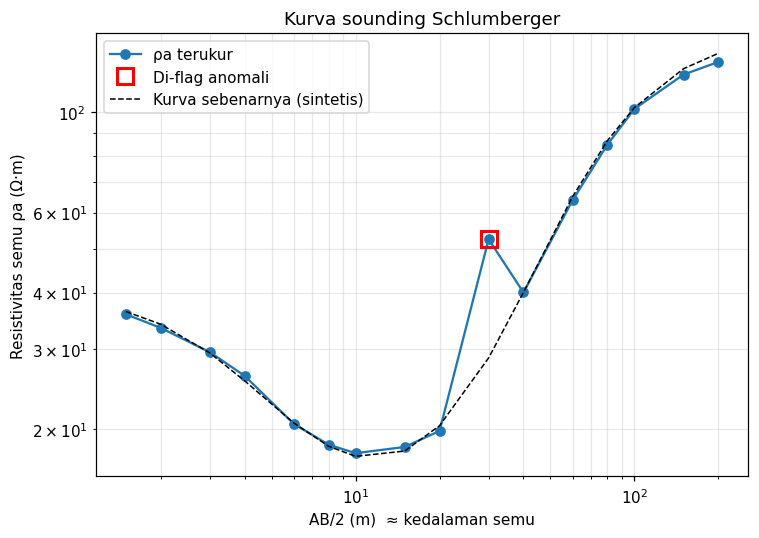

In [25]:
# ============ 4B. Hitung rho_a, flag anomali, kurva sounding ============
res = raw_vi.copy()
res["K (m)"] = k_factor(CONFIG, ab2=res["AB/2 (m)"].to_numpy(), mn2=res["MN/2 (m)"].to_numpy())
res["rho_a (Ohm.m)"] = res["K (m)"] * res["V (mV)"] / res["I (mA)"]

# Flag: fit polinom derajat-4 pada log-log, robust (iterasi), z-score termodifikasi (MAD)
lx, ly = np.log(res["AB/2 (m)"].to_numpy()), np.log(res["rho_a (Ohm.m)"].to_numpy())
good = np.ones(lx.size, bool)
for _ in range(3):
    coef = np.polyfit(lx[good], ly[good], 4)
    resid = ly - np.polyval(coef, lx)
    mad = np.median(np.abs(resid[good] - np.median(resid[good]))) + 1e-9
    z = 0.6745*(resid - np.median(resid[good]))/mad
    good = np.abs(z) < 3.5
res["Residual log"] = resid
res["z-MAD"] = z
res["Flag"] = np.where(good, "", "ANOMALI")

display(res.round(3))
print("Titik di-flag (tidak dihapus):", res.loc[res["Flag"]=="ANOMALI", "AB/2 (m)"].tolist())
print("Catatan: alasan flag = deviasi >3.5 MAD dari kurva halus -> periksa ulang kontak elektroda / pembacaan V.")

fig, ax = plt.subplots(figsize=(7, 5))
ax.loglog(res["AB/2 (m)"], res["rho_a (Ohm.m)"], "o-", color="tab:blue", label="ρa terukur")
bad = res["Flag"] == "ANOMALI"
ax.loglog(res.loc[bad, "AB/2 (m)"], res.loc[bad, "rho_a (Ohm.m)"], "rs", ms=11, mfc="none", mew=2, label="Di-flag anomali")
ax.loglog(AB2, rho_true, "k--", lw=1, label="Kurva sebenarnya (sintetis)")
ax.set_xlabel("AB/2 (m)  ≈ kedalaman semu"); ax.set_ylabel("Resistivitas semu ρa (Ω·m)")
ax.set_title(f"Kurva sounding {CONFIG}"); ax.legend(); ax.grid(True, which="both", alpha=0.3)
plt.tight_layout(); plt.show()

In [26]:
# ============ 4C. Verifikasi (V): hitung manual satu titik ============
j = 5
ab2_, mn2_, I_, V_ = res.loc[j, ["AB/2 (m)", "MN/2 (m)", "I (mA)", "V (mV)"]]
K_manual = np.pi*(ab2_**2 - mn2_**2)/(2*mn2_)
rho_manual = K_manual * V_/I_
print(f"Titik ke-{j}: AB/2 = {ab2_} m, MN/2 = {mn2_} m, I = {I_:.2f} mA, V = {V_:.2f} mV")
print(f"  K   = pi*({ab2_}^2 - {mn2_}^2)/{2*mn2_} = {K_manual:.3f} m")
print(f"  rho = K*V/I = {K_manual:.3f} * {V_:.2f}/{I_:.2f} = {rho_manual:.3f} Ohm.m")
print(f"  Hasil program = {res.loc[j,'rho_a (Ohm.m)']:.3f} Ohm.m -> selisih = {abs(rho_manual-res.loc[j,'rho_a (Ohm.m)']):.2e}")
assert np.isclose(rho_manual, res.loc[j, "rho_a (Ohm.m)"])
print("Interpretasi kualitatif: ρa tinggi -> rendah -> tinggi = lapisan resistif dangkal / konduktif (indikasi akuifer) / basement resistif.")

Titik ke-5: AB/2 = 8.0 m, MN/2 = 1.0 m, I = 50.38 mA, V = 9.41 mV
  K   = pi*(8.0^2 - 1.0^2)/2.0 = 98.960 m
  rho = K*V/I = 98.960 * 9.41/50.38 = 18.493 Ohm.m
  Hasil program = 18.493 Ohm.m -> selisih = 0.00e+00
Interpretasi kualitatif: ρa tinggi -> rendah -> tinggi = lapisan resistif dangkal / konduktif (indikasi akuifer) / basement resistif.


---
# 5. Metode Georadar (GPR) — Konversi Waktu ke Kedalaman

**Prompt (ringkas):** konversi traveltime radargram menjadi kedalaman memakai kecepatan EM, identifikasi reflektor signifikan.

**Rumus**

$$v=\frac{c}{\sqrt{\varepsilon_r}},\quad c = 0{,}2998\ \text{m/ns},\qquad d=\frac{v\,t}{2}$$

($t$ = two-way travel time). Asumsi: $\varepsilon_r = 9$ (tanah lembab/pasir basah) → $v \approx 0{,}100$ m/ns; rentang ketidakpastian $\varepsilon_r = 6$–$12$.

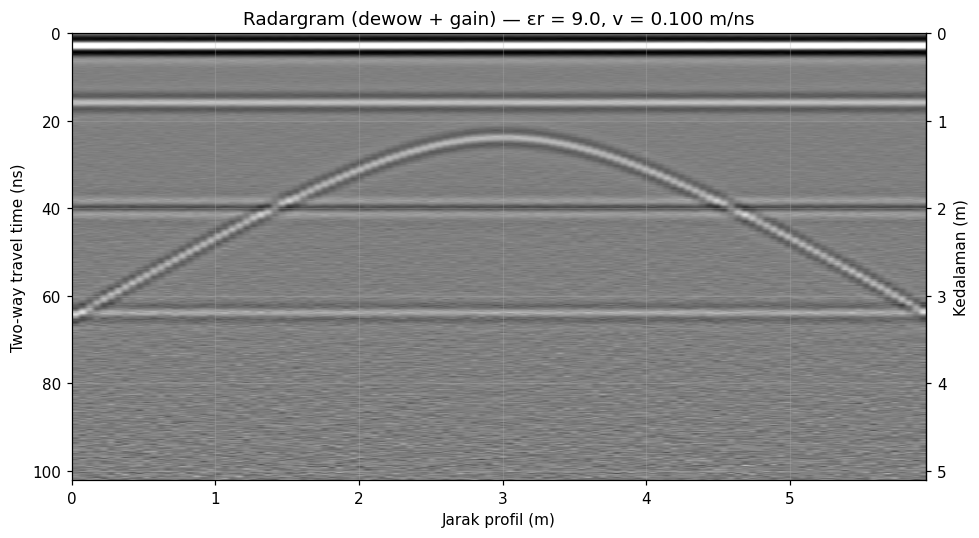

In [27]:
# ============ 5A. Radargram sintetis (B-scan) ============
rng = np.random.default_rng(SEED + 4)

C_LIGHT = 0.2998           # m/ns
EPS_R = 9.0                # >>> asumsi eksplisit (ganti sesuai medium & sumber nilai)
EPS_RANGE = (6.0, 12.0)
V = C_LIGHT/np.sqrt(EPS_R)
F_ANT = 0.25               # GHz (antena 250 MHz)

nx, nt = 120, 512
dx, dt = 0.05, 0.2         # m, ns
xg = np.arange(nx)*dx
tg = np.arange(nt)*dt

def ricker(tt, f):
    a = (np.pi*f*tt)**2
    return (1 - 2*a)*np.exp(-a)

def add_event(data, t_arr, amp):
    t_arr = np.broadcast_to(t_arr, (nx,))
    for j in range(nx):
        data[:, j] += amp*np.exp(-0.02*t_arr[j])*ricker(tg - t_arr[j], F_ANT)

# >>> GANTI DENGAN DATA ANDA: data (nt x nx) hasil import radargram, tg (ns) dan xg (m)
data = np.zeros((nt, nx))
add_event(data, 3.0, 3.0)                                     # gelombang langsung
true_depths = {"R1": 0.8, "R2": 2.0, "R3": 3.2}
add_event(data, 2*0.8/V, 0.9)
add_event(data, 2*2.0/V, -0.7)
add_event(data, 2*3.2/V, 0.6)
x0, zt = 3.0, 1.2                                             # target titik (pipa) -> hiperbola difraksi
add_event(data, 2*np.sqrt(zt**2 + (xg-x0)**2)/V, 0.8)
data += rng.normal(0, 0.03, data.shape)

# Pemrosesan dasar: dewow (hapus drift frekuensi rendah) + gain
def dewow(d, win=25):
    ker = np.ones(win)/win
    return d - np.apply_along_axis(lambda c: np.convolve(c, ker, mode="same"), 0, d)

proc = dewow(data)
gain = np.exp(0.02*tg)[:, None]             # kompensasi atenuasi sederhana (kebalikan model atenuasi)
proc = proc*gain

fig, ax = plt.subplots(figsize=(9, 5))
im = ax.imshow(proc, aspect="auto", cmap="gray", extent=[xg[0], xg[-1], tg[-1], 0],
               vmin=-np.percentile(np.abs(proc), 99), vmax=np.percentile(np.abs(proc), 99))
ax.set_xlabel("Jarak profil (m)"); ax.set_ylabel("Two-way travel time (ns)"); ax.set_title(f"Radargram (dewow + gain) — εr = {EPS_R}, v = {V:.3f} m/ns")
sec = ax.secondary_yaxis("right", functions=(lambda tt: V*tt/2, lambda dd: 2*dd/V))
sec.set_ylabel("Kedalaman (m)")
plt.tight_layout(); plt.show()

,Reflektor,t (ns),d nominal (m),d εr=12 (m),d εr=6 (m),"Kedalaman benar (sintetis, m)"
0,R1,16.200,0.809,0.701,0.991,0.800
1,R2,40.200,2.009,1.740,2.460,2.000
2,R3,64.000,3.198,2.769,3.917,3.200


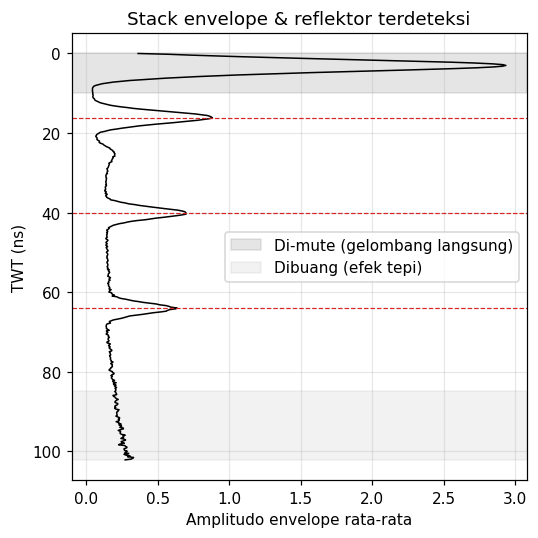

In [28]:
# ============ 5B. Deteksi reflektor (envelope stack) & konversi t -> d ============
def envelope(x):
    # sinyal analitik via FFT (tanpa scipy)
    n = x.shape[0]
    X_ = np.fft.fft(x, axis=0)
    h_ = np.zeros(n); h_[0] = 1
    if n % 2 == 0: h_[n//2] = 1; h_[1:n//2] = 2
    else: h_[1:(n+1)//2] = 2
    return np.abs(np.fft.ifft(X_*h_[:, None], axis=0))

env = envelope(proc)
stack = env.mean(axis=1)                    # rata-rata antar trace -> reflektor lateral kontinu
T_MUTE = 10.0                               # ns: abaikan gelombang langsung + ekor wavelet
T_MAX = 85.0                                # ns: buang bagian akhir (efek tepi dewow/FFT & gain berlebih)
mask = (tg > T_MUTE) & (tg < T_MAX)
s = np.where(mask, stack, 0)
thr = 0.30*s.max()

peaks = [i for i in range(1, nt-1) if s[i] > s[i-1] and s[i] >= s[i+1] and s[i] > thr]
# gabungkan puncak yang terlalu berdekatan (<3 ns): ambil yang terkuat
merged = []
for i in peaks:
    if merged and tg[i] - tg[merged[-1]] < 3.0:
        if s[i] > s[merged[-1]]: merged[-1] = i
    else:
        merged.append(i)
peaks = merged
rows = []
for k, i in enumerate(peaks, 1):
    t_ns = tg[i]
    d_nom = V*t_ns/2
    d_lo = (C_LIGHT/np.sqrt(EPS_RANGE[1]))*t_ns/2      # εr besar -> v kecil -> dangkal
    d_hi = (C_LIGHT/np.sqrt(EPS_RANGE[0]))*t_ns/2
    nearest = min(true_depths.items(), key=lambda kv: abs(kv[1]-d_nom))
    rows.append({"Reflektor": f"R{k}", "t (ns)": t_ns, "d nominal (m)": d_nom,
                 f"d εr={EPS_RANGE[1]:.0f} (m)": d_lo, f"d εr={EPS_RANGE[0]:.0f} (m)": d_hi,
                 "Kedalaman benar (sintetis, m)": nearest[1]})
refl = pd.DataFrame(rows)
display(refl.round(3))

plt.figure(figsize=(5, 5))
plt.plot(stack, tg, color="k", lw=1)
for i in peaks: plt.axhline(tg[i], color="tab:red", ls="--", lw=0.8)
plt.axhspan(0, T_MUTE, color="gray", alpha=0.2, label="Di-mute (gelombang langsung)")
plt.axhspan(T_MAX, tg[-1], color="gray", alpha=0.1, label="Dibuang (efek tepi)")
plt.gca().invert_yaxis(); plt.xlabel("Amplitudo envelope rata-rata"); plt.ylabel("TWT (ns)")
plt.title("Stack envelope & reflektor terdeteksi"); plt.legend(); plt.tight_layout(); plt.show()

In [29]:
# ============ 5C. Contoh numerik & verifikasi (V) ============
t_ex = 40.0
print(f"Contoh: t = {t_ex} ns, εr = {EPS_R}")
print(f"  v = c/sqrt(εr) = {C_LIGHT}/sqrt({EPS_R}) = {V:.4f} m/ns")
print(f"  d = v*t/2      = {V:.4f} * {t_ex}/2 = {V*t_ex/2:.3f} m")
print()
print("Verifikasi terhadap 'ground truth' (kedalaman sintetis):")
for _, r in refl.iterrows():
    err = r["d nominal (m)"] - r["Kedalaman benar (sintetis, m)"]
    print(f"  {r['Reflektor']}: d = {r['d nominal (m)']:.3f} m | benar = {r['Kedalaman benar (sintetis, m)']:.1f} m | galat = {err:+.3f} m")

print("\nObservasi (data)  : reflektor planar kontinu pada ~16, ~40, ~64 ns; hiperbola difraksi berpusat x ≈ 3 m, apeks ≈ 24 ns.")
print("Inferensi (asumsi): batas lapisan pada ~0,8 / 2,0 / 3,2 m dan satu objek titik (mis. pipa) ~1,2 m — bergantung pada εr yang diasumsikan.")
print("Saat memakai data nyata: bandingkan dengan data bor / galian uji untuk mengkalibrasi v.")

Contoh: t = 40.0 ns, εr = 9.0
  v = c/sqrt(εr) = 0.2998/sqrt(9.0) = 0.0999 m/ns
  d = v*t/2      = 0.0999 * 40.0/2 = 1.999 m

Verifikasi terhadap 'ground truth' (kedalaman sintetis):
  R1: d = 0.809 m | benar = 0.8 m | galat = +0.009 m
  R2: d = 2.009 m | benar = 2.0 m | galat = +0.009 m
  R3: d = 3.198 m | benar = 3.2 m | galat = -0.002 m

Observasi (data)  : reflektor planar kontinu pada ~16, ~40, ~64 ns; hiperbola difraksi berpusat x ≈ 3 m, apeks ≈ 24 ns.
Inferensi (asumsi): batas lapisan pada ~0,8 / 2,0 / 3,2 m dan satu objek titik (mis. pipa) ~1,2 m — bergantung pada εr yang diasumsikan.
Saat memakai data nyata: bandingkan dengan data bor / galian uji untuk mengkalibrasi v.


---
# Ringkasan Kriteria Mutu (Q) & Verifikasi (V)

| Metode | Q (terpenuhi) | V (dilakukan) |
|---|---|---|
| Seismik | Rumus & satuan konsisten; Vp eksplisit; alur picking → S−P → regresi → jarak | Contoh numerik satu stasiun; cek dimensi; perbandingan dengan jarak sebenarnya |
| Gravitasi | Penurunan dari kesetimbangan tekanan; SI konsisten; asumsi Airy vs Pratt eksplisit | Cek tekanan & massa kolom dengan `assert`; orde root ≈ puluhan km |
| Geomagnetik | Data mentah tak diubah; satuan nT; IGRF dinyatakan sebagai input dari NOAA | Cek IGRF vs kalkulator resmi; RMSE terhadap anomali sebenarnya |
| Geolistrik | K sesuai konfigurasi; Ω·m konsisten; titik anomali di-flag, tidak dihapus | Hitung manual satu titik (`assert`) |
| Georadar | d = vt/2; asumsi εr + rentang 6–12; observasi vs inferensi dibedakan | Bandingkan dengan kedalaman sebenarnya (sintetis) / data bor (lapangan) |

**Referensi:** Kanamori; Lay & Wallace (seismologi) · Fowler, *The Solid Earth* (isostasi) · NOAA/NGDC IGRF (geomagnetik) · Telford et al. (geolistrik) · Annan; Reynolds (GPR).